<a href="https://colab.research.google.com/github/Asdr30/Machine-Learning-for-Mechanical-Engineering---Neural-Network/blob/main/MLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
!pip install plotstyle
import plotstyle as ps

In [19]:
df = pd.read_csv('resonance_band.csv')
ROOT = Path(".")

In [7]:
df.head(10)

,freq_ratio,damping_ratio,magnification,unacceptable
0,1.2196,0.3130,1.1042,0
1,1.1916,0.3193,1.1505,0
2,1.6914,0.0848,0.5311,0
3,1.4790,0.3529,0.6325,0
4,0.2478,0.3439,1.0483,0
5,0.2890,0.3476,1.0658,0
6,1.2828,0.0556,1.5125,1
7,1.0751,0.2345,1.8948,1
8,0.6683,0.2163,1.6017,1
9,0.9536,0.0616,6.7367,1


In [8]:
df.tail(5)

,freq_ratio,damping_ratio,magnification,unacceptable
595,0.7310,0.4958,1.1607,0
596,1.2239,0.1437,1.6405,1
597,0.7217,0.1110,1.9794,1
598,1.1977,0.0795,2.1079,1
599,1.3194,0.2865,0.9448,0


In [10]:
df.shape

(600, 4)

In [11]:
X, t = df[["freq_ratio", "damping_ratio"]].to_numpy(), df["unacceptable"].to_numpy()
X_tr, X_te, t_tr, t_te = train_test_split(X, t, test_size=0.25, random_state=0, stratify=t)


In [12]:
scaler = StandardScaler().fit(X_tr)            # scale with TRAINING statistics
Z_tr, Z_te = scaler.transform(X_tr), scaler.transform(X_te)


In [13]:
models = {
    "single neuron (2-1)": LogisticRegression(),
    "MLP (2-8-1, tanh)": MLPClassifier(hidden_layer_sizes=(8,), activation="tanh",
                                       solver="lbfgs", max_iter=2000, random_state=1),
}

In [14]:
for name, m in models.items():
    m.fit(Z_tr, t_tr)
    n_par = m.coef_.size + m.intercept_.size if hasattr(m, "coef_") else \
        sum(W.size for W in m.coefs_) + sum(c.size for c in m.intercepts_)
    print(f"{name:22s} parameters = {n_par:3d}   train acc = {m.score(Z_tr, t_tr):.3f}"
          f"   test acc = {m.score(Z_te, t_te):.3f}")
print(f"majority-class baseline: {1 - t_te.mean():.3f}")

single neuron (2-1)    parameters =   3   train acc = 0.773   test acc = 0.807
MLP (2-8-1, tanh)      parameters =  33   train acc = 1.000   test acc = 0.987
majority-class baseline: 0.767


In [15]:
rr, zz = np.meshgrid(np.linspace(0.2, 2.0, 300), np.linspace(0.02, 0.5, 300))
grid = scaler.transform(np.c_[rr.ravel(), zz.ravel()])
M_true = 1 / np.sqrt((1 - rr**2) ** 2 + (2 * zz * rr) ** 2)
cmap = ListedColormap(["#d7efeb", "#f9d9d0"])

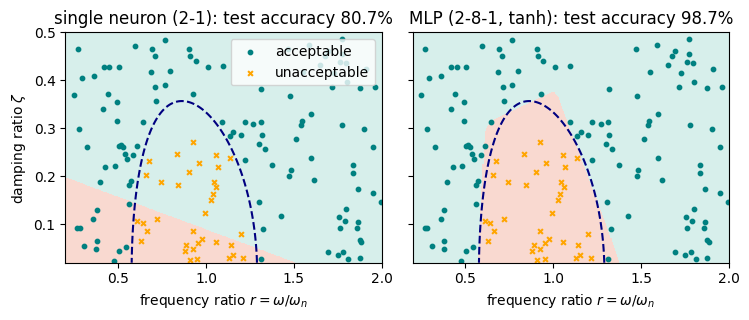

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.3), sharey=True)
for ax, (name, m) in zip(axes, models.items()):
    ax.contourf(rr, zz, m.predict(grid).reshape(rr.shape), levels=[-0.5, 0.5, 1.5], cmap=cmap)
    ax.contour(rr, zz, M_true, levels=[1.5], colors='navy', linestyles="--", linewidths=1.5)
    ax.scatter(*X_te[t_te == 0].T, s=10, c='teal', label="acceptable")
    ax.scatter(*X_te[t_te == 1].T, s=12, c='orange', marker="x", label="unacceptable")
    ax.set(title=f"{name}: test accuracy {m.score(Z_te, t_te):.1%}",
           xlabel=r"frequency ratio $r=\omega/\omega_n$")
    ax.grid(False)
axes[0].set_ylabel(r"damping ratio $\zeta$")
axes[0].legend(loc="upper right", frameon=True)
fig.tight_layout()
fig.savefig(ROOT/"resonance_mlp.pdf")